In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time

from scipy.stats import binom
from matplotlib.ticker import MultipleLocator

In [9]:
#### CONSTANTES FÍSICAS 
## Vamos a trabajar en años
# T12 = 5730.0
# Lambda = np.log(2)/T12

T12 = np.log(2)
Lambda = np.log(2) / T12

n0 = 10**3  # número de núcleos a tiempo 0

t = 5       # tiempo total que vamos a simular
dt = 0.1    # intervalo de tiempo
u = int(t/dt)  # número de intervalos

p = 1 - np.exp(-Lambda * dt)  # probabilidad de desintegración en cada intervalo

# Posición del tiempo de vida media en el array de supervivientes
pos_t12 = int(round(T12 / dt))

num_simulaciones = 500

In [8]:
def simulacion():
    supervivientes = []
    N = n0

    for i in range(u + 1):
        supervivientes.append(N)

        D = np.random.binomial(N, p)
        N -= D

    return supervivientes[pos_t12]


inicio = time.perf_counter()

histograma = []

for i in range(num_simulaciones):
    Num = simulacion()
    histograma.append(Num)

fin = time.perf_counter()

histograma = np.array(histograma)

In [7]:
media_exp = np.mean(histograma)
sigma_exp = np.std(histograma, ddof=1)

print("Media experimental:", media_exp)
print("Desviación estándar experimental:", sigma_exp)

# Tiempo real usado, porque pos_t12 es un índice entero
vidamedia_real = pos_t12 * dt

# Probabilidad de supervivencia hasta ese tiempo
q = np.exp(-Lambda * vidamedia_real)

media_teorica = n0 * q
sigma_teorica = np.sqrt(n0 * q * (1 - q))

k = np.arange(min(histograma), max(histograma) + 1)

frecuencia_teorica = num_simulaciones * binom.pmf(k, n0, q)

bines = 15
anchurabin = (max(histograma) - min(histograma)) / bines

print("Tiempo real usado:", vidamedia_real)
print("Probabilidad de supervivencia q:", q)
print("Media teórica:", media_teorica)
print("Desviación estándar teórica:", sigma_teorica)
print(f"Tiempo de ejecución: {fin - inicio:.2f} segundos")

Media experimental: 496.878
Desviación estándar experimental: 15.93043230256773
Tiempo real usado: 0.7000000000000001
Probabilidad de supervivencia q: 0.49658530379140947
Media teórica: 496.58530379140944
Desviación estándar teórica: 15.811019570217573
Tiempo de ejecución: 0.04 segundos


In [5]:
np.savetxt("TEST.txt", histograma)

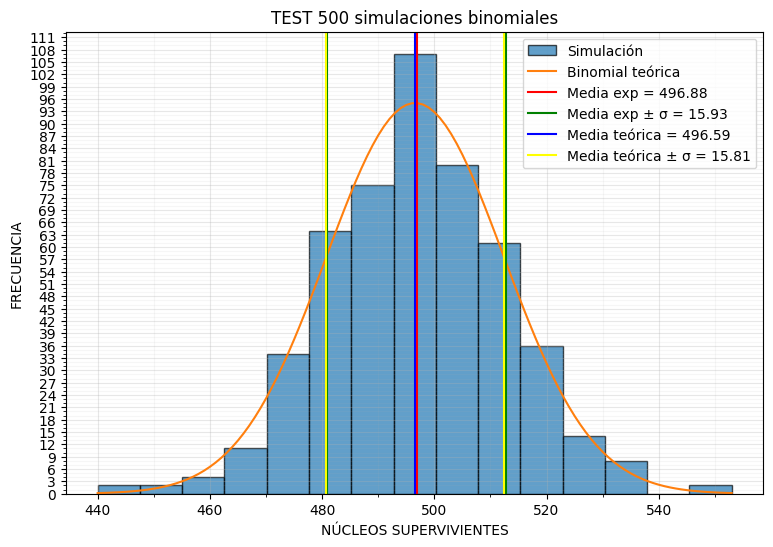

In [6]:
plt.figure(figsize=(9, 6))

## HISTOGRAMA
plt.hist(
    histograma,
    bins=bines,
    edgecolor="black",
    alpha=0.7,
    label="Simulación"
)

## CURVA TEÓRICA BINOMIAL
plt.plot(
    k,
    frecuencia_teorica * anchurabin,
    "-",
    label="Binomial teórica"
)

## LÍNEAS VERTICALES PARA MEDIA Y DESVIACIÓN ESTÁNDAR EXPERIMENTAL

plt.axvline(
    media_exp,
    color="red",
    linestyle="-",
    label=f"Media exp = {media_exp:.2f}"
)

plt.axvline(
    media_exp + sigma_exp,
    color="green",
    linestyle="-",
    label=f"Media exp ± σ = {sigma_exp:.2f}"
)

plt.axvline(
    media_exp - sigma_exp,
    color="green",
    linestyle="-"
)

## LÍNEAS VERTICALES PARA MEDIA Y DESVIACIÓN ESTÁNDAR TEÓRICA

plt.axvline(
    media_teorica,
    color="blue",
    linestyle="-",
    label=f"Media teórica = {media_teorica:.2f}"
)

plt.axvline(
    media_teorica + sigma_teorica,
    color="yellow",
    linestyle="-",
    label=f"Media teórica ± σ = {sigma_teorica:.2f}"
)

plt.axvline(
    media_teorica - sigma_teorica,
    color="yellow",
    linestyle="-"
)


###############################################
## CONFIGURACIÓN DE LA GRÁFICA 
##############################################


plt.title("TEST 500 simulaciones binomiales")
plt.xlabel("NÚCLEOS SUPERVIVIENTES")
plt.ylabel("FRECUENCIA")
plt.legend()

ax = plt.gca()

ax.xaxis.set_major_locator(MultipleLocator(20))
ax.xaxis.set_minor_locator(MultipleLocator(10))

ax.yaxis.set_major_locator(MultipleLocator(3))
ax.yaxis.set_minor_locator(MultipleLocator(1))

plt.grid(True, which="major", alpha=0.3)
plt.grid(True, which="minor", alpha=0.1)

plt.savefig("TEST.png", dpi=300, bbox_inches="tight")
plt.show()